# Phenotype-associated cells from bulk cohorts with Scissor

Clinical phenotypes such as survival or mutation status are measured on large bulk cohorts (for example TCGA), while single-cell data come from a handful of patients. **Scissor** (Sun *et al.*, *Nat Biotechnol* 2022) links the two: it correlates every cell with every bulk sample and fits a network-regularised regression of the bulk phenotype on these correlations. Cells with a non-zero coefficient are selected — **Scissor+** cells point towards the phenotype coded as positive (mutant, higher hazard) and **Scissor−** cells towards the other one; all remaining cells are *background*.

`ov.single.Scissor` wraps the independent, R-free [`scissor_py`](https://github.com/omicverse/py-Scissors) backend (numerically validated against the original R package on the full LUAD data used here). Three regression families are supported:

| `family=` | Phenotype | Scissor+ means |
|---|---|---|
| `'cox'` | `time` / `status` (1 event, 0 censored) | higher hazard (worse survival) |
| `'binomial'` | two classes + `positive_label` | the positive class |
| `'gaussian'` | continuous value | higher value |

This tutorial reproduces the two lung adenocarcinoma (LUAD) analyses of the [official Scissor tutorial](https://sunduanchen.github.io/Scissor/vignettes/Scissor_Tutorial.html) and of the paper with real data: 4,102 LUAD cancer cells guided by (1) overall survival of 471 TCGA-LUAD patients (Cox) and (2) *TP53* mutation status of 498 TCGA-LUAD tumours (binomial). The official example data contain no continuous phenotype, so `family='gaussian'` is only described, not run.

The backend is an optional dependency; install it once into the notebook's environment:

```sh
pip install "git+https://github.com/omicverse/py-Scissors.git@cc630ae828149202b553fb7dfdaeda2d0b94d1d7"
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import omicverse as ov

ov.plot_set()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. Data

The five input files of the official tutorial (`scRNA-seq.RData`, `TCGA_LUAD_exp1/exp2.RData`, `TCGA_LUAD_survival.RData`, `TCGA_LUAD_TP53_mutation.RData`, hosted by the Scissor authors) were converted to `.h5ad` without removing any cell, sample or gene (conversion script and SHA-256 of the source files are in the [`scissor-v1` release](https://github.com/omicverse/omicverse-data/releases/tag/scissor-v1)).

* `scissor_luad_sc.h5ad` — raw UMI counts of 4,102 LUAD **cancer cells** × 33,694 genes (Lambrechts *et al.*, *Nat Med* 2018); the suffix of each barcode is the sample.
* `scissor_luad_bulk_survival.h5ad` — 471 TCGA-LUAD tumours × 56,716 genes with `obs['time']` (days) and `obs['status']`.
* `scissor_luad_bulk_tp53.h5ad` — 498 TCGA-LUAD tumours × 56,716 genes with `obs['TP53']` (`'mutant'` / `'wild-type'`).

In [2]:
url = 'https://github.com/omicverse/omicverse-data/releases/download/scissor-v1/'
files = ['scissor_luad_sc.h5ad', 'scissor_luad_bulk_survival.h5ad', 'scissor_luad_bulk_tp53.h5ad']
paths = [ov.datasets.download_data(url + f, dir='data/scissor') for f in files]
adata, bulk_os, bulk_tp53 = [ov.read(p) for p in paths]
adata

🔍 Downloading data to data/scissor/scissor_luad_sc.h5ad
⚠️ File data/scissor/scissor_luad_sc.h5ad already exists
🔍 Downloading data to data/scissor/scissor_luad_bulk_survival.h5ad
⚠️ File data/scissor/scissor_luad_bulk_survival.h5ad already exists
🔍 Downloading data to data/scissor/scissor_luad_bulk_tp53.h5ad
⚠️ File data/scissor/scissor_luad_bulk_tp53.h5ad already exists


AnnData object with n_obs × n_vars = 4102 × 33694
    obs: 'patient_batch'
    uns: 'source'

In [3]:
print(bulk_os.shape, bulk_os.obs['status'].value_counts().to_dict())
print(bulk_tp53.shape, bulk_tp53.obs['TP53'].value_counts().to_dict())

(471, 56716) {0: 350, 1: 121}
(498, 56716) {'mutant': 255, 'wild-type': 243}


## 2. Single-cell preprocessing and cell graph

Scissor needs two things from the single-cell side, and both are explicit choices made here, not inside `Scissor`:

1. **an expression layer** used for the cell–bulk correlations. As in the official pipeline (Seurat `NormalizeData`), we use log1p(counts per 10,000) of **all** genes (`exclude_highly_expressed=False` keeps every gene in the size factor, as Seurat does), stored in `layers['lognorm']`;
2. **a cell–cell graph** for the network penalty, which encourages neighbouring cells to receive similar coefficients. We build a 20-nearest-neighbour graph on 10 principal components of 2,000 highly variable genes (the official tutorial uses Seurat's SNN graph on the same 10 PCs). Scissor binarises the graph, so only the set of edges matters.

In [4]:
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', target_sum=1e4,
                         n_HVGs=2000, identify_robust=False,
                         exclude_highly_expressed=False)
adata.layers['lognorm'] = adata.X.copy()
adata.raw = adata

🔍 [2026-10-12 17:16:50] Running preprocessing in 'cpu' mode...
Begin robust gene identification
Begin size normalization: shiftlog and HVGs selection pearson

🔍 Count Normalization:
   Target sum: 10000.0
   Exclude highly expressed: False

✅ Count Normalization Completed Successfully!
   ✓ Processed: 4,102 cells × 33,694 genes
   ✓ Runtime: 0.07s

🔍 Highly Variable Genes Selection (Experimental):
   Method: pearson_residuals
   Target genes: 2,000
   Theta (overdispersion): 100



✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 33,694 total (5.9%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 1.87 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ────────────────────

In [5]:
ov.pp.scale(adata)
ov.pp.pca(adata, n_pcs=10, layer='scaled')
ov.pp.neighbors(adata, n_neighbors=20, n_pcs=10, use_rep='scaled|original|X_pca')
ov.pp.umap(adata)
ov.pp.leiden(adata, resolution=0.6)


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 1.3794s                                                 │
│  Shape:    4,102 x 33,694 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (array, 4102x33694)                           │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
computing PCA🔍
    with n_comps=10
   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (4102, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (1.76s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 1.7658s                                                 │
│  Shape:    4,102 x 33,694 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 4102x10)                               │
│           │ ✚ scaled|original|X_pca (array, 4102x10)               │
│         

   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 4,102 cells with 20 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 4.8799s                                                 │
│  Shape:    4,102 x 33,694 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ neighbors                                            │
│           │ └─ params: {'n_neighbors': 20, 'method': 'umap', 'random_s...│
│                                                                    │
│  ● OBSP   │ ✚ connectivit


✅ UMAP Dimensionality Reduction Completed Successfully!
   ✓ Embedding shape: 4,102 cells × 2 dimensions
   ✓ Results added to AnnData object:
     • 'X_umap': UMAP coordinates (adata.obsm)
     • 'umap': UMAP parameters (adata.uns)
✅ UMAP completed successfully.

╭─ SUMMARY: umap ────────────────────────────────────────────────────╮
│  Duration: 0.9568s                                                 │
│  Shape:    4,102 x 33,694 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ umap                                                 │
│           │ └─ params: {'a': 0.5830300199950147, 'b': 1.334166993228519}│
│                                                                    │
│  ● OBSM   │ ✚ X_umap (array, 4102x2)                               │
│                  

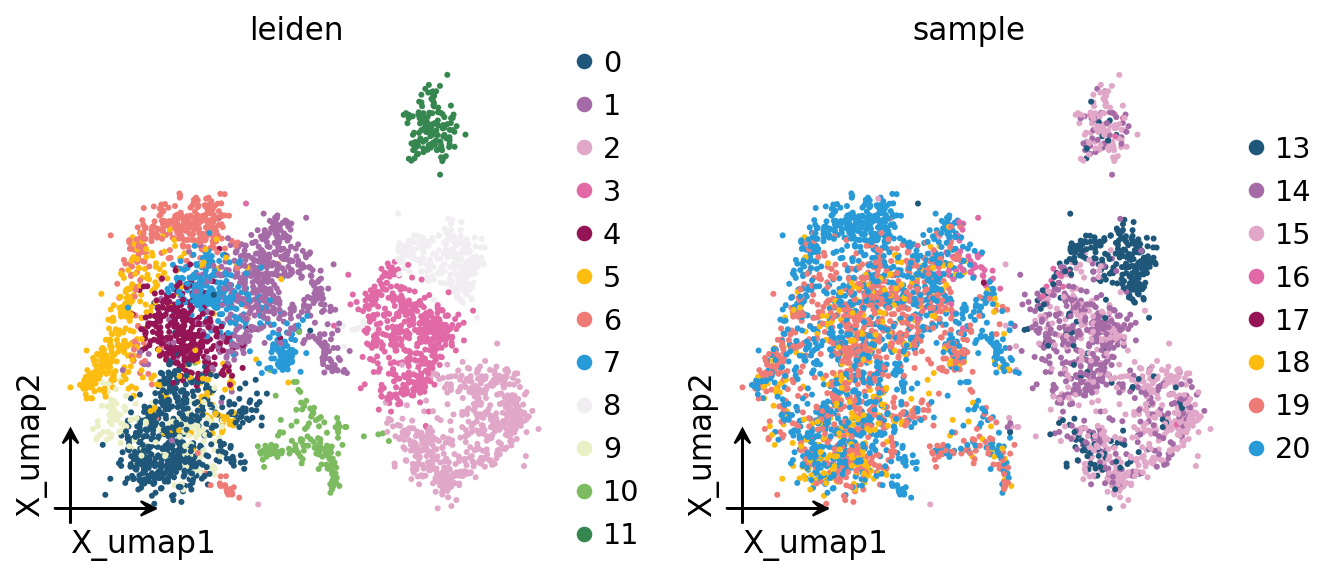

In [6]:
adata.obs['sample'] = adata.obs['patient_batch']
ov.pl.embedding(adata, basis='X_umap', color=['leiden', 'sample'], wspace=0.35, frameon='small')

The 4,102 cancer cells form 14 Leiden clusters. Several clusters are dominated by one sample (patients differ strongly in tumour-intrinsic programmes), which is expected for malignant cells and is why Scissor scores cells individually rather than clusters.

## 3. Bulk expression and phenotype

`Scissor` expects bulk expression as a **genes × samples** DataFrame with unique gene IDs, and refuses duplicated IDs instead of guessing how to merge them. The TCGA matrices contain 1,485 duplicated gene symbols; the original R implementation implicitly uses the first row of each symbol, so we make the same choice explicitly. Shared genes between bulk and single-cell data are then intersected inside Scissor (22,323 genes here).

For Cox regression the phenotype is a DataFrame with exactly the columns `time` and `status`, indexed by the bulk sample IDs.

In [7]:
def bulk_frame(bdata):
    expr = bdata.to_df().T
    return expr[~expr.index.duplicated(keep='first')]

expr_os = bulk_frame(bulk_os)
pheno_os = bulk_os.obs[['time', 'status']]
expr_os.shape, int(pheno_os['status'].sum())

((55231, 471), 121)

## 4. Cells associated with worse survival (Cox)

Key parameters:

* `alpha` — balance between the L1 (sparsity) and the network penalty. Larger `alpha` selects fewer cells. A list is searched in order and the first `alpha` whose selected fraction is below `cutoff` is kept (default `cutoff=0.2`, i.e. at most 20 % of cells). We use the official value `alpha=0.05`.
* `semantics` — `'official'` reproduces the published R code exactly, but the R code indexes the graph unsafely for the Cox and Gaussian families on a connected graph, so `scissor_py` refuses that combination. `'corrected'` fixes the indexing (and a few numerical details, see the [semantics notes](https://github.com/omicverse/py-Scissors/blob/cc630ae828149202b553fb7dfdaeda2d0b94d1d7/docs/SEMANTICS.md)) and is required here.
* `lambda` is chosen by 10-fold cross-validation (`nfolds`, `nlambda=100` as in R). `max_dense_bytes` raises the guard for the dense 4,102 × 22,323 expression matrix (~0.7 GB).

In [8]:
cox = ov.single.Scissor(adata, bulk=expr_os, phenotype=pheno_os, family='cox',
                        layer='lognorm', graph_key='connectivities',
                        semantics='corrected', key_added='scissor_os')
res_os = cox.run(alpha=0.05, nfolds=10, random_state=123, max_dense_bytes=4_000_000_000)
print(f"alpha = {res_os.alpha}, lambda = {res_os.lambda_min:.4f}")
adata.obs['scissor_os'].value_counts()

alpha = 0.05, lambda = 0.0407


scissor_os
background    3916
Scissor+       183
Scissor-         3
Name: count, dtype: int64

Scissor selects **183 Scissor+ cells (worse survival) and 3 Scissor− cells** (4.5 % of all cells) at `lambda = 0.041`. The official R tutorial reports 201 Scissor+ and 4 Scissor− cells at `lambda = 0.042` with Seurat's SNN graph — the same strongly one-sided picture: almost all phenotype-associated cancer cells point to worse survival.

In [9]:
vignette_pos = ['AAAGTAGAGGAGCGAG_19', 'AACCATGCATCTCCCA_19', 'AACCGCGAGCTGCGAA_20', 'AACTCAGTCCGCGGTA_19']
vignette_neg = ['ACGCCAGTCCTCCTAG_20', 'ACGGGCTAGTGGCACA_20', 'CCGGTAGGTACCCAAT_15', 'GACGCGTAGTGGTCCC_20']
print('vignette Scissor+ cells:', adata.obs.loc[vignette_pos, 'scissor_os'].tolist())
print('vignette Scissor- cells:', adata.obs.loc[vignette_neg, 'scissor_os'].tolist())

vignette Scissor+ cells: ['Scissor+', 'background', 'Scissor+', 'Scissor+']
vignette Scissor- cells: ['background', 'background', 'Scissor-', 'background']


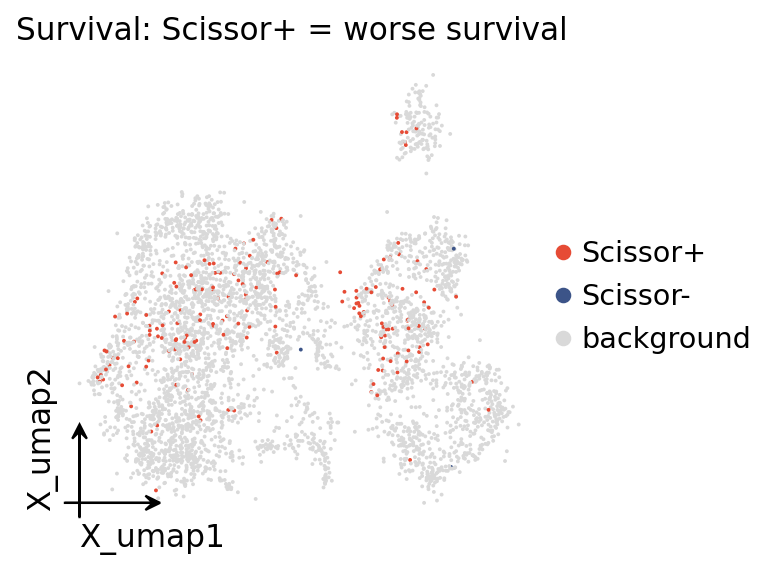

In [10]:
palette = {'Scissor+': '#e64b35', 'Scissor-': '#3c5488', 'background': '#d9d9d9'}
ov.pl.embedding(adata, basis='X_umap', color='scissor_os', palette=palette,
                size=12, frameon='small', title='Survival: Scissor+ = worse survival')

In [11]:
pd.crosstab(adata.obs['leiden'], adata.obs['scissor_os']).query('`Scissor+` > 0')

scissor_os,Scissor+,Scissor-,background
leiden,,,
0,7,0,567
1,39,0,505
2,4,1,512
3,54,0,416
4,26,0,314
5,22,0,308
7,15,1,285
8,6,1,239
9,3,0,162


Three of the four Scissor+ example cells printed in the official tutorial are also Scissor+ here, and one of its four Scissor− cells is Scissor− here. Scissor+ cells are spread over several clusters rather than forming one cluster (most in clusters 3 and 1), as in the paper (Fig. 2c) — the selection is driven by the bulk phenotype, not by the clustering.

### What characterises the worse-survival cells?

The paper reports that Scissor+ cells for survival over-express **hypoxia** genes (HIF1A targets, glycolysis). We test this with a Wilcoxon test of Scissor+ cells against all other cells and with AUCell scores of Hallmark gene sets (MSigDB v7.5.1, shipped with OmicVerse).

In [12]:
ov.single.find_markers(adata, groupby='scissor_os', method='wilcoxon', groups=['Scissor+'],
                       reference='rest', n_genes=adata.n_vars, key_added='de_os')
de_os = ov.single.get_markers(adata, n_genes=adata.n_vars, key='de_os', groups='Scissor+').set_index('names')
de_os.head(25)

🔍 Finding marker genes | method: wilcoxon | groupby: scissor_os | n_groups: 1 | n_genes: 33694


✅ Done | 1 groups × 33694 genes | corr: benjamini-hochberg | stored in adata.uns['de_os']


,group,rank,scores,logfoldchanges,pvals,pvals_adj,pct_group,pct_rest
names,,,,,,,,
ACTB,Scissor+,1,14.290646,1.321827,2.502796e-46,8.432922e-42,0.983607,0.947436
GAPDH,Scissor+,2,13.104388,1.073944,3.107589e-39,5.235355e-35,0.994536,0.979587
TMSB10,Scissor+,3,12.331845,0.829094,6.103260e-35,6.854775e-31,1.000000,0.993110
ACTG1,Scissor+,4,10.877761,1.161736,1.471328e-27,9.914986e-24,0.945355,0.881092
ENO1,Scissor+,5,9.297202,1.183642,1.441901e-20,6.940487e-17,0.868852,0.803776
ALDOA,Scissor+,6,9.041316,1.110048,1.547964e-19,6.519637e-16,0.885246,0.786935
TPI1,Scissor+,7,9.025575,0.848470,1.787543e-19,6.692163e-16,0.885246,0.847155
PKM,Scissor+,8,6.986440,0.930471,2.819494e-12,7.307694e-09,0.748634,0.692779
CALM2,Scissor+,9,6.611775,0.705601,3.797387e-11,8.529944e-08,0.901639,0.864761


The top up-regulated genes of the worse-survival cells include the glycolytic enzymes *ENO1*, *ALDOA*, *TPI1*, *PKM*, *LDHA* (and *GAPDH*, *PGK1* further down) — classic HIF-1 targets.

In [13]:
hallmark = ov.datasets.load_signatures_from_file(ov.datasets.predefined_signatures['hallmark'])
sets = ['HALLMARK_HYPOXIA', 'HALLMARK_GLYCOLYSIS', 'HALLMARK_E2F_TARGETS', 'HALLMARK_G2M_CHECKPOINT']
for s in sets:
    ov.single.geneset_aucell(adata, s, hallmark[s])
sets = [s + '_aucell' for s in sets]

Loaded signatures from GMT file .../site-packages/omicverse/datasets/data_files/h.all.v7.5.1.symbols.gmt.
[ov.single AUCell] The new GPU-accelerated API is `ov.es.aucell` — pass signatures as a dict, e.g. `ov.es.aucell(adata, signatures={'name': genes}, engine='gpu')`. The legacy function still works.


[ov.single AUCell] The new GPU-accelerated API is `ov.es.aucell` — pass signatures as a dict, e.g. `ov.es.aucell(adata, signatures={'name': genes}, engine='gpu')`. The legacy function still works.


[ov.single AUCell] The new GPU-accelerated API is `ov.es.aucell` — pass signatures as a dict, e.g. `ov.es.aucell(adata, signatures={'name': genes}, engine='gpu')`. The legacy function still works.


[ov.single AUCell] The new GPU-accelerated API is `ov.es.aucell` — pass signatures as a dict, e.g. `ov.es.aucell(adata, signatures={'name': genes}, engine='gpu')`. The legacy function still works.


In [14]:
from scipy.stats import mannwhitneyu

def compare_scores(obs, key, case, ref):
    a, b = obs[obs[key] == case], obs[obs[key].isin(ref)]
    return pd.DataFrame({'mean ' + case: a[sets].mean(), 'mean reference': b[sets].mean(),
                         'Mann-Whitney p': [mannwhitneyu(a[s], b[s]).pvalue for s in sets]})

compare_scores(adata.obs, 'scissor_os', 'Scissor+', ['background', 'Scissor-'])

,mean Scissor+,mean reference,Mann-Whitney p
HALLMARK_HYPOXIA_aucell,0.031206,0.026526,1.743260e-11
HALLMARK_GLYCOLYSIS_aucell,0.027614,0.022625,1.591808e-11
HALLMARK_E2F_TARGETS_aucell,0.018462,0.015457,5.036091e-05
HALLMARK_G2M_CHECKPOINT_aucell,0.013030,0.011581,2.811712e-04


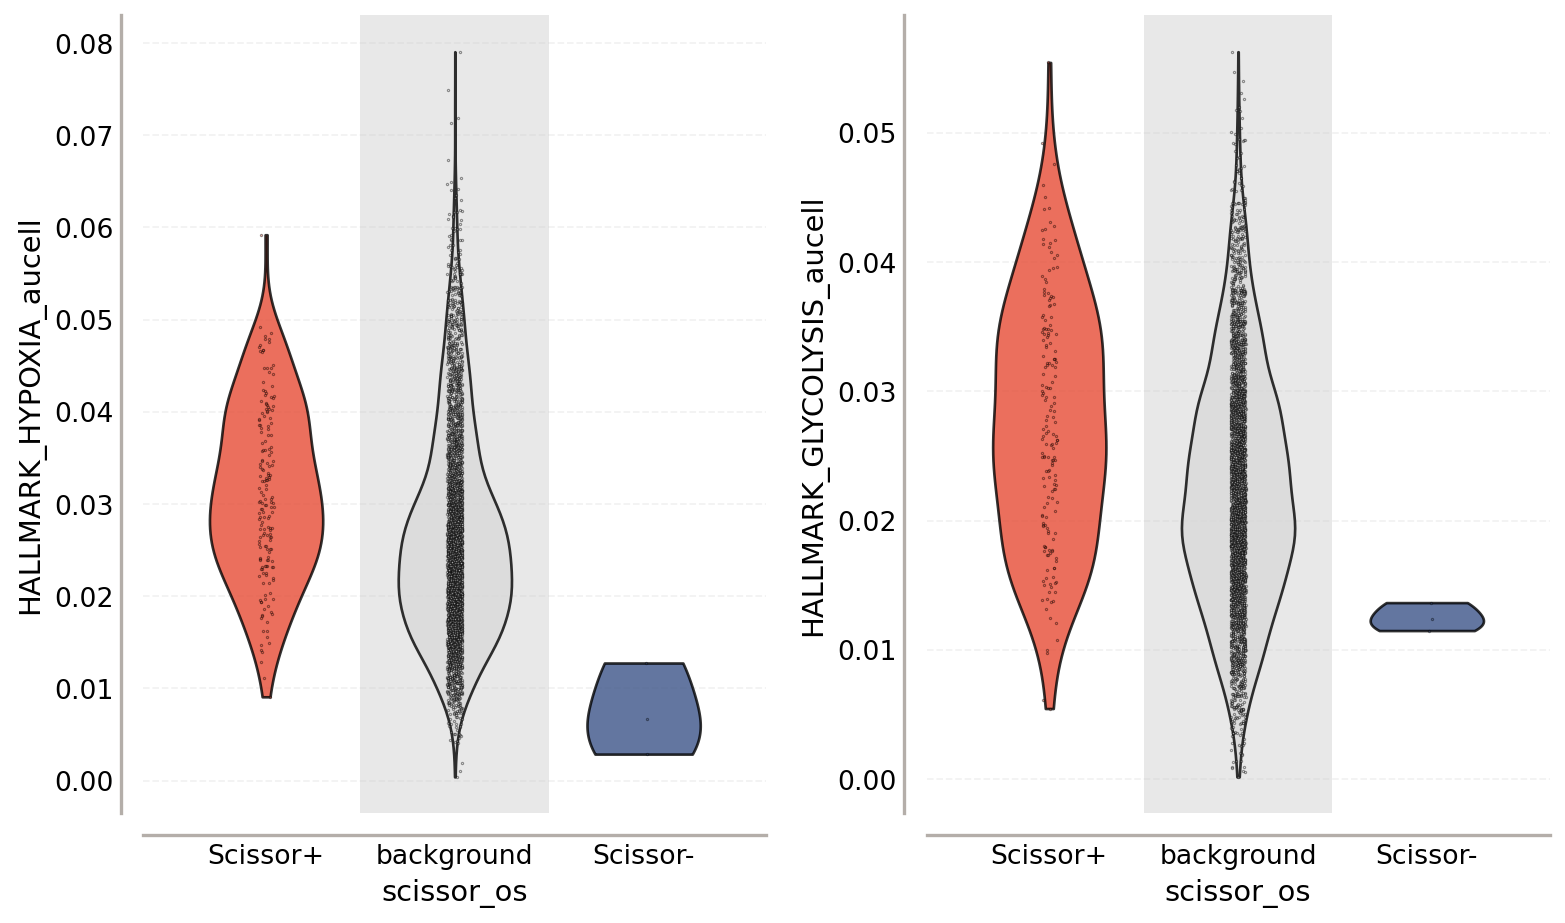

In [15]:
order = ['Scissor+', 'background', 'Scissor-']
ov.pl.violin(adata, keys=['HALLMARK_HYPOXIA_aucell', 'HALLMARK_GLYCOLYSIS_aucell'], groupby='scissor_os',
             order=order, custom_colors=[palette[g] for g in order])

Scissor+ cells have higher Hallmark hypoxia and glycolysis activity than the other cells (Mann–Whitney p ≈ 2e-11 for both), in line with the hypoxic, glycolytic subpopulation reported by Sun *et al.* (Fig. 2e,f). Cell-cycle programmes (E2F, G2M) differ much less.

### Is this a sequencing-depth artefact?

Scissor+ cells of the survival model have fewer detected genes than the other cells. After library-size normalisation, low-depth cells show inflated values for the most highly expressed genes — and glycolytic enzymes are among them. To rule this out, we compare the Scissor+ cells with background cells **matched for the number of detected genes** (same decile, five background cells per Scissor+ cell).

In [16]:
obs = adata.obs.assign(n_genes=np.asarray((adata.layers['counts'] > 0).sum(1)).ravel())
obs['depth_bin'] = pd.qcut(obs['n_genes'], 10, labels=False)
pos = obs[obs['scissor_os'] == 'Scissor+']
bg = obs[obs['scissor_os'] == 'background']
matched = pd.concat([bg[bg['depth_bin'] == b].sample(min(5 * n, (bg['depth_bin'] == b).sum()), random_state=0)
                     for b, n in pos['depth_bin'].value_counts().items()])

In [17]:
print('median detected genes  Scissor+:', pos['n_genes'].median(), ' all background:', bg['n_genes'].median(),
      ' matched background:', matched['n_genes'].median())
compare_scores(pd.concat([pos, matched]), 'scissor_os', 'Scissor+', ['background'])

median detected genes  Scissor+: 649.0  all background: 955.5  matched background: 670.0


,mean Scissor+,mean reference,Mann-Whitney p
HALLMARK_HYPOXIA_aucell,0.031206,0.023645,6.728566e-23
HALLMARK_GLYCOLYSIS_aucell,0.027614,0.020517,1.547577e-19
HALLMARK_E2F_TARGETS_aucell,0.018462,0.015971,2.730587e-03
HALLMARK_G2M_CHECKPOINT_aucell,0.013030,0.011956,8.941775e-03


The Scissor+ cells indeed have fewer detected genes (median 649 vs 956). Against depth-matched background cells (median 670) the hypoxia and glycolysis differences become even stronger (p ≈ 7e-23 and 2e-19), whereas E2F/G2M differences shrink to p ≈ 0.003–0.009. The hypoxic signature is therefore not a sequencing-depth artefact.

## 5. Cells associated with *TP53* mutation (binomial)

For a binary phenotype the sign of a coefficient depends on how the two classes are coded, so `positive_label` must be given for string labels: here Scissor+ cells point towards `'mutant'` and Scissor− cells towards `'wild-type'`. The binomial model of the R code is safe on any graph, so we keep `semantics='official'`. As in the paper we use `alpha=0.2`.

In [18]:
expr_tp53 = bulk_frame(bulk_tp53)
pheno_tp53 = bulk_tp53.obs['TP53']
tp53 = ov.single.Scissor(adata, bulk=expr_tp53, phenotype=pheno_tp53, family='binomial',
                         positive_label='mutant', layer='lognorm', graph_key='connectivities',
                         semantics='official', key_added='scissor_tp53')

In [19]:
res_tp53 = tp53.run(alpha=0.2, nfolds=10, random_state=123, max_dense_bytes=4_000_000_000)
print(f"alpha = {res_tp53.alpha}, lambda = {res_tp53.lambda_min:.4f}")
adata.obs['scissor_tp53'].value_counts()

alpha = 0.2, lambda = 0.0011


scissor_tp53
background    3174
Scissor+       523
Scissor-       405
Name: count, dtype: int64

**523 Scissor+ (TP53-mutant-like) and 405 Scissor− (wild-type-like) cells** are selected (22.6 % of cells); the official tutorial reports 414 and 318 at the same `alpha`. Unlike survival, both directions are well represented. Together they make up more than the default `cutoff=0.2`; with a single `alpha` this is only reported (`res_tp53.cutoff_reached` is `False`), not changed — pass a list of alphas to let Scissor search for a sparser solution.

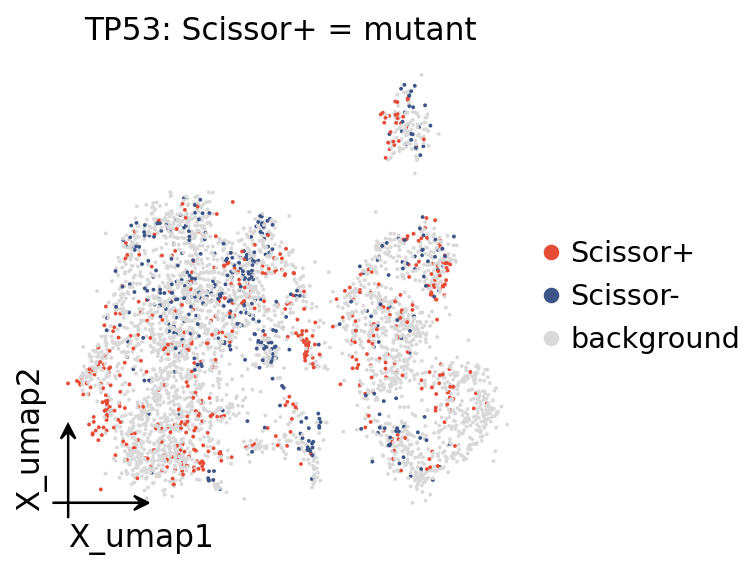

In [20]:
ov.pl.embedding(adata, basis='X_umap', color='scissor_tp53', palette=palette,
                size=12, frameon='small', title='TP53: Scissor+ = mutant')

The paper compares Scissor+ with Scissor− cells and finds E2F targets and cell-cycle genes (*AURKA*, *CDK1*, *CCNB2*, *TOP2A*) up in the mutant-associated cells, consistent with loss of p53-mediated cell-cycle arrest.

In [21]:
ov.single.find_markers(adata, groupby='scissor_tp53', method='wilcoxon', groups=['Scissor+'],
                       reference='Scissor-', n_genes=adata.n_vars, key_added='de_tp53')
de_tp53 = ov.single.get_markers(adata, n_genes=adata.n_vars, key='de_tp53', groups='Scissor+').set_index('names')
de_tp53.loc[['AURKA', 'CDK1', 'CCNB2', 'TOP2A', 'MKI67']]

🔍 Finding marker genes | method: wilcoxon | groupby: scissor_tp53 | n_groups: 1 | n_genes: 33694


✅ Done | 2 groups × 33694 genes | corr: benjamini-hochberg | stored in adata.uns['de_tp53']


,group,rank,scores,logfoldchanges,pvals,pvals_adj,pct_group
names,,,,,,,
AURKA,Scissor+,447,5.300725,2.988688,1.153435e-07,7.788344e-06,0.229446
CDK1,Scissor+,931,4.612483,1.809119,3.978870e-06,1.348733e-04,0.250478
CCNB2,Scissor+,406,5.375674,3.194646,7.629678e-08,5.612977e-06,0.229446
TOP2A,Scissor+,27,7.308901,2.720919,2.693353e-13,1.374998e-10,0.351816
MKI67,Scissor+,219,5.819685,5.315138,5.895854e-09,7.325101e-07,0.233270


In [22]:
compare_scores(adata.obs, 'scissor_tp53', 'Scissor+', ['Scissor-'])

,mean Scissor+,mean reference,Mann-Whitney p
HALLMARK_HYPOXIA_aucell,0.025584,0.022395,6.740174e-06
HALLMARK_GLYCOLYSIS_aucell,0.022602,0.019206,1.779462e-09
HALLMARK_E2F_TARGETS_aucell,0.022185,0.012575,2.944850e-26
HALLMARK_G2M_CHECKPOINT_aucell,0.017045,0.009376,1.016963e-29


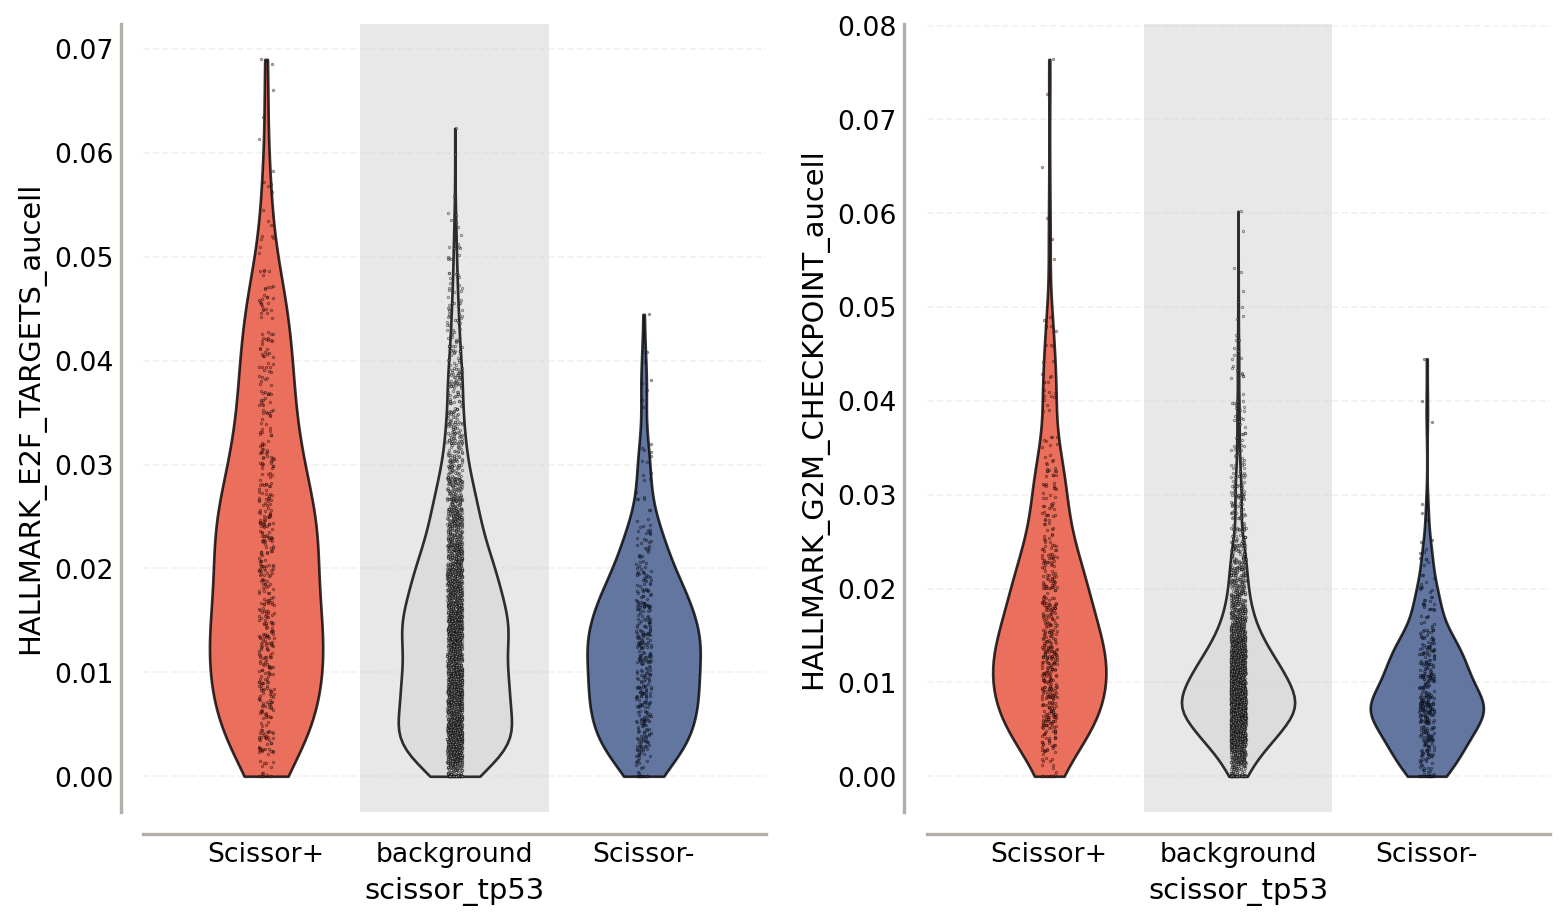

In [23]:
ov.pl.violin(adata, keys=['HALLMARK_E2F_TARGETS_aucell', 'HALLMARK_G2M_CHECKPOINT_aucell'], groupby='scissor_tp53',
             order=order, custom_colors=[palette[g] for g in order])

All four cell-cycle genes highlighted in the paper are significantly higher in mutant-associated than in wild-type-associated cells (FDR ≤ 1.4e-4; *TOP2A* is the 27th-ranked gene), and the E2F-target and G2M-checkpoint scores show the largest differences (p ≈ 3e-26 and 1e-29), reproducing the proliferative, E2F-driven state of *TP53*-mutant cells in Sun *et al.* (Fig. 3b,c).

## 6. Comparing both analyses

The two phenotypes select largely different cells: the survival model highlights a hypoxic state, the *TP53* model a proliferative state.

In [24]:
pd.crosstab(adata.obs['scissor_os'], adata.obs['scissor_tp53'])

scissor_tp53,Scissor+,Scissor-,background
scissor_os,,,
Scissor+,30,9,144
Scissor-,0,3,0
background,493,393,3030


Only 30 cells are Scissor+ in both analyses; most survival-associated (hypoxic) cells are not selected by the *TP53* model, which instead picks a proliferative population.

## 7. What is stored and how to save it

Each run writes `obs[key]` (`Scissor+` / `Scissor-` / `background`), `obs[key + '_coef']` and an audit record in `uns[key]` (parameters, backend versions, phenotype encoding, cross-validation curves and the SHA-256 of the normalised graph). Running again with the same `key_added` raises an error unless `overwrite=True`, so a result is never silently replaced. The returned `ScissorResult` keeps the coefficients, the selected `lambda` and the per-alpha cross-validation results; below, the CV curve of the survival model with the selected `lambda` (dashed).

In [25]:
print(adata.obs[['scissor_os', 'scissor_os_coef']].query('scissor_os != "background"').head())
print(list(adata.uns['scissor_os'].keys()))
print(adata.uns['scissor_tp53']['encoding'])

                    scissor_os  scissor_os_coef
AAACGGGAGTCCATAC_19   Scissor+         0.000446
AAAGTAGAGGAGCGAG_19   Scissor+         0.005339
AACCGCGAGCTGCGAA_20   Scissor+         0.002132
AACTCAGTCCGCGGTA_19   Scissor+         0.000337
AACTCCCAGCGCCTTG_19   Scissor+         0.012826
['schema_version', 'result_json', 'params', 'encoding', 'sharedgenes', 'source', 'CV', 'convergence', 'versions', 'json_fields']
{"negative":"wild-type","positive":"mutant"}


[Text(0.5, 0, 'log(lambda)'),
 Text(0, 0.5, '10-fold CV loss'),
 Text(0.5, 1.0, 'Cox, alpha = 0.05')]

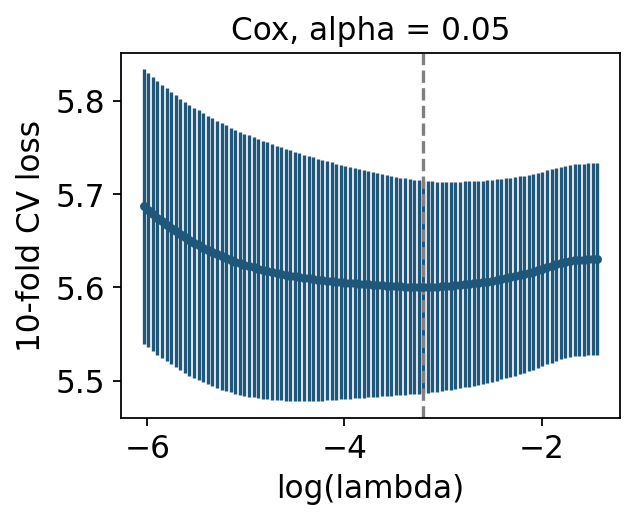

In [26]:
cv = res_os.cv_results[0]
fig, ax = plt.subplots(figsize=(4, 3))
ax.errorbar(np.log(cv.path.lambdas), cv.mean_loss, yerr=cv.standard_error, fmt='o', ms=3)
ax.axvline(np.log(cv.lambda_min), ls='--', c='grey')
ax.set(xlabel='log(lambda)', ylabel='10-fold CV loss', title=f'Cox, alpha = {cv.path.alpha}')

The cross-validation curve is shallow relative to its standard errors: the selected `lambda` is the minimum of a broad valley. The number of selected cells therefore depends on `lambda` (and on the graph and `alpha`), so report these settings together with the selected cells.

## Notes and limitations

* **Graph.** Scissor's result depends on the cell graph. We used a 20-NN graph on 10 PCs; the official tutorial used Seurat's SNN graph, which is why the cell counts are close to but not identical with the published ones (201 / 4 for survival, 414 / 318 for *TP53*).
* **Alpha and cutoff.** Pass a list, e.g. `alpha=[0.005, 0.01, 0.05, 0.1, 0.2]` with `cutoff=0.03`, to let Scissor pick the first alpha that selects < 3 % of cells. Each alpha costs one full cross-validation (about 2 min here).
* **Semantics.** Use `'official'` to reproduce the R package where it is well defined (binomial); `'corrected'` is required for Cox and Gaussian on a connected graph.
* **Interpretation.** Selected cells are associated with the bulk phenotype through similarity; this is neither causal nor patient-level evidence. The original package additionally offers a permutation reliability test (`reliability.test`), which is not part of `ov.single.Scissor`.
* **Gaussian.** For a continuous phenotype pass a numeric `pd.Series` indexed by bulk sample with `family='gaussian'`; Scissor+ cells then point to higher values. `engine='numba'` accelerates the corrected Gaussian solver.